# Module 2 — Nettoyage et préparation des données

**Projet :** House Prices — Advanced Regression Techniques  
**Source :** Kaggle  
**Objectif :** diagnostiquer la qualité des données, définir des règles de nettoyage justifiées et produire des jeux de travail cohérents pour la préparation à la modélisation.

---

## Périmètre et principes de travail

- Les fichiers `train.csv` et `test.csv` sont chargés séparément.
- Les DataFrames sources `df_train` et `df_test` sont conservés sans modification.
- Les transformations sont appliquées uniquement aux copies `df_train_clean` et `df_test_clean`.
- Les décisions de traitement sont fondées sur la signification des variables et documentées dans le notebook.
- Les paramètres d'imputation sont calculés à partir du jeu d'entraînement, puis réutilisés sur le jeu de test afin de limiter les fuites de données.

**Convention :** `SalePrice` est la variable cible disponible uniquement dans le jeu d'entraînement.


In [56]:
# 1. Importation des bibliothèques
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Outils de préparation des variables pour le Machine Learning
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split


In [57]:
# 2. Localisation du répertoire des données
candidate_paths = [
    Path.cwd() / "data" / "bronze",
    Path.cwd().parent / "data" / "bronze",
]

DATA_DIR = next((path for path in candidate_paths if path.is_dir()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Dossier 'data/bronze' introuvable. "
        "Placez les fichiers Kaggle dans data/bronze ou adaptez DATA_DIR."
    )

print(f"Dossier des données : {DATA_DIR.resolve()}")

Dossier des données : C:\Users\hp\Downloads\house-prices-advanced-regression-techniques\data\bronze


In [58]:
# 3. Chargement des jeux de données
files = {
    "train": "train.csv",
    "test": "test.csv",
    "sample_submission": "sample_submission.csv",
}

dataframes = {}

for name, filename in files.items():
    file_path = DATA_DIR / filename
    if not file_path.is_file():
        raise FileNotFoundError(f"Fichier introuvable : {file_path}")
    dataframes[name] = pd.read_csv(file_path)

df_train = dataframes["train"]
df_test = dataframes["test"]
df_submission = dataframes["sample_submission"]

print("Chargement terminé.")
print(f"Train : {df_train.shape[0]:,} lignes × {df_train.shape[1]} colonnes")
print(f"Test  : {df_test.shape[0]:,} lignes × {df_test.shape[1]} colonnes")
print(f"Submission : {df_submission.shape[0]:,} lignes × {df_submission.shape[1]} colonnes")

Chargement terminé.
Train : 1,460 lignes × 81 colonnes
Test  : 1,459 lignes × 80 colonnes
Submission : 1,459 lignes × 2 colonnes


## 4. Diagnostic de la qualité des données

Les contrôles sont effectués séparément sur `train` et `test`. Le fichier `sample_submission` sert uniquement de modèle de format pour la soumission Kaggle : il n'est pas utilisé pour diagnostiquer les caractéristiques des maisons.

### 4.1 Analyse des valeurs manquantes

Le taux de valeurs manquantes est calculé pour chaque variable. Cette mesure permet de distinguer les variables peu renseignées de celles dont l'information est presque complète.

**Point d'attention :** une valeur manquante ne signifie pas toujours une donnée inconnue. Dans le jeu House Prices, certaines absences peuvent représenter l'absence réelle d'un équipement ou d'une caractéristique. La stratégie de traitement doit donc tenir compte de la définition de chaque variable.

In [59]:
def create_quality_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Calcule le nombre et le pourcentage de valeurs manquantes par variable."""
    missing_count = df.isna().sum()
    summary = pd.DataFrame({
        "Valeurs manquantes": missing_count,
        "Pourcentage manquant (%)": (missing_count / len(df) * 100).round(2)
    })
    return (
        summary.loc[summary["Valeurs manquantes"] > 0]
        .sort_values("Pourcentage manquant (%)", ascending=False)
    )

for name, df in {"train": df_train, "test": df_test}.items():
    print(f"\\nValeurs manquantes — {name.upper()}")
    summary = create_quality_summary(df)
    if summary.empty:
        print("Aucune valeur manquante détectée.")
    else:
        display(summary)

\nValeurs manquantes — TRAIN


,Valeurs manquantes,Pourcentage manquant (%)
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


\nValeurs manquantes — TEST


,Valeurs manquantes,Pourcentage manquant (%)
PoolQC,1456,99.79
MiscFeature,1408,96.50
Alley,1352,92.67
Fence,1169,80.12
MasVnrType,894,61.27
FireplaceQu,730,50.03
LotFrontage,227,15.56
GarageCond,78,5.35
GarageYrBlt,78,5.35
GarageQual,78,5.35


### 4.2 Détection des valeurs potentiellement aberrantes

La méthode de l'écart interquartile (IQR) identifie les observations situées en dehors des bornes statistiques :

- borne inférieure : Q1 − 1,5 × IQR ;
- borne supérieure : Q3 + 1,5 × IQR ;
- IQR : Q3 − Q1.

Une observation détectée comme aberrante n'est pas nécessairement erronée. Elle doit être examinée au regard du contexte de la variable avant toute suppression ou transformation.

> **Interprétation :**la méthode IQR signale des valeurs extrêmes, pas nécessairement des erreurs. Dans l'immobilier, une grande surface ou un prix élevé peut être réel. Il faut examiner les observations avant toute correction.

In [60]:
def detect_outliers(
    df: pd.DataFrame,
    exclude_columns: tuple = ("Id",)
) -> pd.DataFrame:
    """Repère les valeurs situées hors des bornes IQR, sans les supprimer."""
    results = []

    numeric_columns = df.select_dtypes(include="number").columns.difference(
        list(exclude_columns)
    )

    for col in numeric_columns:
        series = df[col].dropna()
        if series.empty:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = series[(series < lower_bound) | (series > upper_bound)]

        results.append({
            "Variable": col,
            "Nombre de valeurs détectées": int(len(outliers)),
            "Pourcentage (%)": round(len(outliers) / len(series) * 100, 2),
            "Borne inférieure": round(lower_bound, 2),
            "Borne supérieure": round(upper_bound, 2),
        })

    return pd.DataFrame(results).sort_values(
        "Nombre de valeurs détectées", ascending=False
    ) if results else pd.DataFrame()

for name, df in {"train": df_train, "test": df_test}.items():
    print(f"\\nValeurs potentiellement aberrantes — {name.upper()}")
    result = detect_outliers(df)
    if result.empty:
        print("Aucune variable numérique à analyser.")
    else:
        display(result)

\nValeurs potentiellement aberrantes — TRAIN


,Variable,Nombre de valeurs détectées,Pourcentage (%),Borne inférieure,Borne supérieure
9,EnclosedPorch,208,14.25,0.00,0.00
5,BsmtFinSF2,167,11.44,0.00,0.00
26,OverallCond,125,8.56,3.50,7.50
30,ScreenPorch,116,7.95,0.00,0.00
21,MSSubClass,103,7.05,-55.00,145.00
22,MasVnrArea,96,6.61,-249.00,415.00
19,LotFrontage,88,7.33,27.50,111.50
7,BsmtHalfBath,82,5.62,0.00,0.00
25,OpenPorchSF,77,5.27,-102.00,170.00
18,LotArea,69,4.73,1481.50,17673.50


\nValeurs potentiellement aberrantes — TEST


,Variable,Nombre de valeurs détectées,Pourcentage (%),Borne inférieure,Borne supérieure
9,EnclosedPorch,251,17.20,0.00,0.00
5,BsmtFinSF2,180,12.35,0.00,0.00
29,ScreenPorch,140,9.60,0.00,0.00
26,OverallCond,127,8.70,3.50,7.50
21,MSSubClass,104,7.13,-55.00,145.00
22,MasVnrArea,102,7.06,-246.00,410.00
19,LotFrontage,100,8.12,25.00,113.00
7,BsmtHalfBath,93,6.38,0.00,0.00
25,OpenPorchSF,79,5.41,-108.00,180.00
17,KitchenAbvGr,66,4.52,1.00,1.00


### 4.3 Vérification de certaines incohérences

Les contrôles ci-dessous recherchent notamment :
- les chaînes de caractères vides ;
- les espaces superflus au début ou à la fin des chaînes ;
- les valeurs numériques infinies.

Ces vérifications constituent un premier diagnostic. Elles ne remplacent pas la validation métier des valeurs et des modalités.

In [61]:
def detect_inconsistencies(df: pd.DataFrame) -> pd.DataFrame:
    """Détecte des incohérences simples de format et des valeurs infinies."""
    results = []

    for col in df.columns:
        series = df[col]

        if pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series):
            empty_values = series.map(
                lambda value: isinstance(value, str) and value.strip() == ""
            ).sum()
            spaces_values = series.map(
                lambda value: isinstance(value, str) and value != value.strip()
            ).sum()

            if empty_values:
                results.append({"Variable": col, "Type d'incohérence": "Chaînes vides", "Nombre": int(empty_values)})
            if spaces_values:
                results.append({"Variable": col, "Type d'incohérence": "Espaces superflus", "Nombre": int(spaces_values)})

        if pd.api.types.is_numeric_dtype(series):
            infinite_values = np.isinf(series.dropna()).sum()
            if infinite_values:
                results.append({"Variable": col, "Type d'incohérence": "Valeurs infinies", "Nombre": int(infinite_values)})

    return pd.DataFrame(results, columns=["Variable", "Type d'incohérence", "Nombre"])

for name, df in {"train": df_train, "test": df_test}.items():
    print(f"\nIncohérences simples — {name.upper()}")
    result = detect_inconsistencies(df)
    if result.empty:
        print("Aucune incohérence détectée avec les contrôles effectués.")
    else:
        display(result)


Incohérences simples — TRAIN


Aucune incohérence détectée avec les contrôles effectués.

Incohérences simples — TEST
Aucune incohérence détectée avec les contrôles effectués.


In [62]:
for name, df in dataframes.items():

    print(f"\nVérification des incohérences — {name.upper()}")

    inconsistencies = detect_inconsistencies(df)

    if not inconsistencies.empty:
        display(inconsistencies)
    else:
        print("Aucune incohérence détectée avec les contrôles effectués.")


Vérification des incohérences — TRAIN
Aucune incohérence détectée avec les contrôles effectués.

Vérification des incohérences — TEST
Aucune incohérence détectée avec les contrôles effectués.

Vérification des incohérences — SAMPLE_SUBMISSION
Aucune incohérence détectée avec les contrôles effectués.


## 5. Analyse et traitement des valeurs manquantes

Le traitement doit être décidé **variable par variable**. Une valeur manquante peut représenter une absence réelle, une information inconnue ou une donnée non collectée.

| Situation | Traitement possible | Précaution |
|---|---|---|
| L'absence signifie que l'équipement n'existe pas | Modalité `None` pour une variable catégorielle | Confirmer dans le dictionnaire |
| Variable numérique avec valeurs inconnues | Médiane, éventuellement par groupe | Ajuster l'imputation uniquement sur train |
| Variable catégorielle inconnue | Modalité `Inconnue` ou mode | Ne pas confondre absence et inconnue |
| Variable très incomplète | Étudier son sens et son utilité | Ne pas supprimer automatiquement |
| Cible `SalePrice` manquante | Ne pas imputer pour l'apprentissage supervisé | Une ligne sans cible ne permet pas d'entraîner le modèle |

**Important :** aucune imputation statistique n'est effectuée à cette étape. Les décisions sont documentées avant application.

In [63]:
# 5.1 Rapport détaillé des valeurs manquantes

def missing_values_report(df: pd.DataFrame) -> pd.DataFrame:
    """Présente les valeurs manquantes, leur taux et le type de variable."""
    report = pd.DataFrame({
        "Nombre manquant": df.isna().sum(),
        "Taux manquant (%)": (df.isna().mean() * 100).round(2),
        "Type": df.dtypes.astype(str),
    })
    return report.loc[report["Nombre manquant"] > 0].sort_values(
        "Taux manquant (%)", ascending=False
    )

for dataset_name, dataset in {"train": df_train, "test": df_test}.items():
    print(f"\\nRapport des valeurs manquantes — {dataset_name.upper()}")
    report = missing_values_report(dataset)
    if report.empty:
        print("Aucune valeur manquante détectée.")
    else:
        display(report)

# 5.2 Copies de travail : les fichiers sources restent intacts.
df_train_clean = df_train.copy()
df_test_clean = df_test.copy()

print("Copies de travail créées : df_train_clean et df_test_clean.")
print("Aucune imputation automatique n'a encore été appliquée.")

\nRapport des valeurs manquantes — TRAIN


,Nombre manquant,Taux manquant (%),Type
PoolQC,1453,99.52,object
MiscFeature,1406,96.30,object
Alley,1369,93.77,object
Fence,1179,80.75,object
MasVnrType,872,59.73,object
FireplaceQu,690,47.26,object
LotFrontage,259,17.74,float64
GarageType,81,5.55,object
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,object


\nRapport des valeurs manquantes — TEST


,Nombre manquant,Taux manquant (%),Type
PoolQC,1456,99.79,object
MiscFeature,1408,96.50,object
Alley,1352,92.67,object
Fence,1169,80.12,object
MasVnrType,894,61.27,object
FireplaceQu,730,50.03,object
LotFrontage,227,15.56,float64
GarageCond,78,5.35,object
GarageYrBlt,78,5.35,float64
GarageQual,78,5.35,object


Copies de travail créées : df_train_clean et df_test_clean.
Aucune imputation automatique n'a encore été appliquée.


### 5.3 Repérer les variables fortement incomplètes

Le seuil de 50 % sert uniquement à attirer l'attention. Il ne constitue pas une règle automatique de suppression.

In [64]:
missing_rate = df_train.isna().mean().mul(100)
high_missing_columns = missing_rate[missing_rate > 50].sort_values(ascending=False)

if high_missing_columns.empty:
    print("Aucune variable ne dépasse 50 % de valeurs manquantes.")
else:
    display(high_missing_columns.to_frame("Taux de valeurs manquantes (%)"))

,Taux de valeurs manquantes (%)
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027


### 5.4 Interpréter les valeurs manquantes

Pour chaque variable fortement incomplète, consulter le dictionnaire Kaggle (`data_description.txt`) et déterminer si NaN signifie :

- une absence réelle d'un équipement ;
- une information inconnue ;
- une information qui n'a pas été renseignée ;
- une situation particulière liée à la propriété.

Cette étape est indispensable : remplacer toutes les valeurs manquantes par la même valeur pourrait créer une information incorrecte.

#### Exemples de variables où NaN peut signifier une absence

| Variable | Interprétation possible de NaN | Traitement à envisager |
|---|---|---|
| `PoolQC` | Aucune piscine | `None` |
| `Alley` | Aucun accès par ruelle | `None` |
| `Fence` | Aucune clôture | `None` |
| `FireplaceQu` | Aucune cheminée | `None` |
| `MiscFeature` | Aucune caractéristique supplémentaire | `None` |
| `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond` | Aucun garage | `None` |
| `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2` | Aucun sous-sol | `None` |

Ces interprétations doivent être vérifiées avec le dictionnaire des données avant le traitement.

### 5.5 Étude descriptive de la variable `PoolQC`

On prend `PoolQC` comme exemple. La comparaison ci-dessous permet de décrire les prix des maisons selon que la qualité de la piscine est renseignée ou non. Elle ne prouve pas, à elle seule, une relation de causalité.

In [65]:
# Comparaison descriptive pour PoolQC
if "PoolQC" not in df_train.columns or "SalePrice" not in df_train.columns:
    raise KeyError("Les colonnes 'PoolQC' et 'SalePrice' doivent être présentes dans train.")

df_analysis = df_train[["PoolQC", "SalePrice"]].copy()
df_analysis["PoolQC_missing"] = df_analysis["PoolQC"].isna()

price_comparison = (
    df_analysis.groupby("PoolQC_missing")["SalePrice"]
    .agg(["count", "mean", "median", "std"])
    .rename(index={False: "PoolQC renseignée", True: "PoolQC manquante"})
)
display(price_comparison)

print(
    "Attention : le groupe PoolQC renseignée peut contenir très peu "
    "d'observations. Vérifiez toujours l'effectif avant d'interpréter "
    "les moyennes et les écarts-types."
)

,count,mean,median,std
PoolQC_missing,,,,
PoolQC renseignée,7,288138.571429,235000.0,206071.850935
PoolQC manquante,1453,180404.663455,162900.0,78168.872519


Attention : le groupe PoolQC renseignée peut contenir très peu d'observations. Vérifiez toujours l'effectif avant d'interpréter les moyennes et les écarts-types.


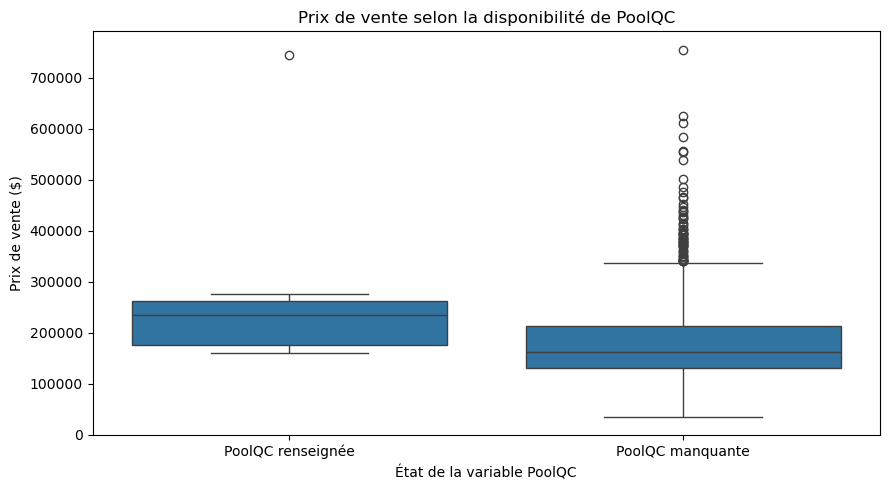

In [66]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_analysis, x="PoolQC_missing", y="SalePrice")
plt.xticks([0, 1], ["PoolQC renseignée", "PoolQC manquante"])
plt.title("Prix de vente selon la disponibilité de PoolQC")
plt.xlabel("État de la variable PoolQC")
plt.ylabel("Prix de vente ($)")
plt.tight_layout()
plt.show()

### Interprétation de l'exemple `PoolQC`

Dans ce jeu de données, `PoolQC` décrit la qualité de la piscine. Une valeur manquante correspond généralement à l'absence de piscine, et non à une qualité inconnue.

La comparaison des prix peut montrer une différence entre les maisons avec piscine et celles sans piscine. Cependant, le nombre de maisons dont `PoolQC` est renseignée est très faible (7 dans le diagnostic observé). Les statistiques de ce petit groupe sont donc sensibles à quelques observations et doivent être interprétées avec prudence.

**Décision de préparation :** conserver `PoolQC` et remplacer les valeurs manquantes par la modalité `None`, après vérification de cette signification dans le dictionnaire des données. Cela permet de distinguer les maisons sans piscine de celles qui en possèdent une avec une qualité renseignée.

In [67]:
# Le traitement de PoolQC est désormais intégré à MISSING_MEANS_ABSENCE
# et sera appliqué avec les autres variables catégorielles dans la section 5.6.1.
print("PoolQC sera traité dans la règle générale des absences catégorielles.")


PoolQC sera traité dans la règle générale des absences catégorielles.


### 5.6 Application de la stratégie d'imputation

Les règles ci-dessous sont appliquées aux copies de travail. Les variables sont traitées selon leur signification : absence d'équipement, absence numérique ou information inconnue.

Les listes de variables sont limitées aux colonnes effectivement présentes dans les deux jeux de données. Les statistiques utilisées pour l'imputation sont calculées sur `df_train_clean` uniquement.


#### 5.6.1 Variables catégorielles représentant une absence
Dans ce dataset, certaines maisons ne possèdent tout simplement pas certains équipements.

| Variable | Signification de la valeur manquante | Traitement |
|---|---|---|
| `PoolQC` | Pas de piscine | `"None"` |
| `MiscFeature` | Pas d'équipement particulier | `"None"` |
| `Alley` | Pas d'accès par une ruelle | `"None"` |
| `Fence` | Pas de clôture | `"None"` |
| `FireplaceQu` | Pas de cheminée | `"None"` |
| `MasVnrType` | Pas de revêtement en maçonnerie | `"None"` |
| `GarageType` | Pas de garage | `"None"` |
| `GarageFinish` | Pas de garage | `"None"` |
| `GarageQual` | Pas de garage | `"None"` |
| `GarageCond` | Pas de garage | `"None"` |
| `BsmtQual` | Pas de sous-sol | `"None"` |
| `BsmtCond` | Pas de sous-sol | `"None"` |
| `BsmtExposure` | Pas de sous-sol | `"None"` |
| `BsmtFinType1` | Pas de sous-sol | `"None"` |
| `BsmtFinType2` | Pas de sous-sol | `"None"` |

Les variables sont catégorielles. On peut donc utiliser la modalité "None" pour représenter l'absence réelle de l'équipement.

#### 5.6.2 Variables numériques représentant une absence
Certaines variables numériques doivent recevoir 0 lorsque l'équipement correspondant n'existe pas.

| Variable | Signification | Traitement |
|---|---|---|
| `MasVnrArea` | Surface de maçonnerie absente | `0` |
| `BsmtFinSF1` | Surface aménagée du sous-sol | `0` |
| `BsmtFinSF2` | Surface aménagée secondaire | `0` |
| `BsmtUnfSF` | Surface non aménagée du sous-sol | `0` |
| `TotalBsmtSF` | Surface totale du sous-sol | `0` |
| `BsmtFullBath` | Nombre de salles de bain complètes au sous-sol | `0` |
| `BsmtHalfBath` | Nombre de demi-salles de bain au sous-sol | `0` |
| `GarageCars` | Nombre de voitures dans le garage | `0` |
| `GarageArea` | Surface du garage | `0` |

#### 5.6.3 Variables nécessitant une imputation statistique
Certaines informations sont inconnues. Il faut alors utiliser une méthode statistique.

| Variable | Type | Traitement recommandé |
|---|---|---|
| `LotFrontage` | Numérique | Médiane par quartier (`Neighborhood`) |
| `GarageYrBlt` | Numérique | Médiane + indicateur de valeur manquante |
| `Electrical` | Catégorielle | Mode du train |
| `MSZoning` | Catégorielle | Mode du train |
| `Functional` | Catégorielle | Mode du train |
| `KitchenQual` | Catégorielle | Mode du train |
| `Utilities` | Catégorielle | Mode du train |
| `Exterior1st` | Catégorielle | Mode du train |
| `Exterior2nd` | Catégorielle | Mode du train |
| `SaleType` | Catégorielle | Mode du train |

Pour `LotFrontage`, la médiane par quartier est utilisée afin de tenir compte des différences possibles entre quartiers. Une médiane globale sert de solution de repli si un quartier ne dispose d'aucune valeur exploitable.

**Règle 1 — Remplacer les absences catégorielles et numériques**

Le dictionnaire `MISSING_MEANS_ABSENCE` centralise les variables pour lesquelles `NaN` représente l'absence réelle d'un équipement. Il définit la valeur de remplacement adaptée au type de variable : la modalité `None` pour une variable catégorielle et `0` pour une variable numérique. Les remplacements sont appliqués séparément à `df_train_clean` et `df_test_clean`.

In [68]:
# 5.6.1 Définir et appliquer les absences catégorielles
# Dans ces colonnes, une valeur manquante signifie que l'équipement n'existe pas.
MISSING_MEANS_ABSENCE = {
    "categorical": {
        "PoolQC": "None",       # Le logement ne possède pas de piscine
        "MiscFeature": "None",  # Aucun équipement particulier
        "Alley": "None",        # Pas d'accès par une ruelle
        "Fence": "None",        # Pas de clôture
        "FireplaceQu": "None",  # Pas de cheminée
        "MasVnrType": "None",   # Pas de revêtement en maçonnerie
        "GarageType": "None",   # Pas de garage
        "GarageFinish": "None",
        "GarageQual": "None",
        "GarageCond": "None",
        "BsmtQual": "None",     # Pas de sous-sol
        "BsmtCond": "None",
        "BsmtExposure": "None",
        "BsmtFinType1": "None",
        "BsmtFinType2": "None",
    },
    "numeric": {
        "MasVnrArea": 0,        # Aucune surface de maçonnerie
        "BsmtFinSF1": 0,        # Pas de surface de sous-sol aménagée de type 1
        "BsmtFinSF2": 0,        # Pas de surface de sous-sol aménagée de type 2
        "BsmtUnfSF": 0,         # Pas de surface de sous-sol non aménagée
        "TotalBsmtSF": 0,       # Pas de sous-sol
        "BsmtFullBath": 0,      # Pas de salle de bain complète au sous-sol
        "BsmtHalfBath": 0,      # Pas de demi-salle de bain au sous-sol
        "GarageCars": 0,        # Pas de garage / aucune place de garage
        "GarageArea": 0,        # Aucune surface de garage
    },
}

# Appliquer les règles aux copies de travail, sans modifier les fichiers sources.
imputation_counts = {"categorical": {}, "numeric": {}}

for col, replacement in MISSING_MEANS_ABSENCE["categorical"].items():
    for dataset_name, dataset in (
        ("train", df_train_clean),
        ("test", df_test_clean),
    ):
        if col in dataset.columns:
            count = int(dataset[col].isna().sum())
            dataset[col] = dataset[col].fillna(replacement)
            imputation_counts["categorical"].setdefault(col, {})[dataset_name] = count

print("Traitement des absences catégorielles terminé.")
print("Nombre de valeurs remplacées par variable :")
display(pd.DataFrame(imputation_counts["categorical"]).T.fillna(0).astype(int))


Traitement des absences catégorielles terminé.
Nombre de valeurs remplacées par variable :


,train,test
PoolQC,1453,1456
MiscFeature,1406,1408
Alley,1369,1352
Fence,1179,1169
FireplaceQu,690,730
MasVnrType,872,894
GarageType,81,76
GarageFinish,81,78
GarageQual,81,78
GarageCond,81,78


**Règle 2 — Remplacer les absences numériques**

In [69]:
# 5.6.2 Appliquer les absences numériques
# Ici, zéro représente une absence réelle d'équipement ou de surface.
for col, replacement in MISSING_MEANS_ABSENCE["numeric"].items():
    for dataset_name, dataset in (
        ("train", df_train_clean),
        ("test", df_test_clean),
    ):
        if col in dataset.columns:
            count = int(dataset[col].isna().sum())
            dataset[col] = dataset[col].fillna(replacement)
            imputation_counts["numeric"].setdefault(col, {})[dataset_name] = count

print("Traitement des absences numériques terminé.")
print("Nombre de valeurs remplacées par variable :")
display(pd.DataFrame(imputation_counts["numeric"]).T.fillna(0).astype(int))


Traitement des absences numériques terminé.
Nombre de valeurs remplacées par variable :


,train,test
MasVnrArea,8,15
BsmtFinSF1,0,1
BsmtFinSF2,0,1
BsmtUnfSF,0,1
TotalBsmtSF,0,1
BsmtFullBath,0,2
BsmtHalfBath,0,2
GarageCars,0,1
GarageArea,0,1


**Règle 3 — Imputer `LotFrontage` par quartier**

In [70]:
# Les médianes par quartier sont estimées sur le train uniquement.
if "LotFrontage" in df_train_clean.columns and "Neighborhood" in df_train_clean.columns:
    lot_frontage_median_by_neighborhood = (
        df_train_clean.groupby("Neighborhood")["LotFrontage"].median()
    )
    lot_frontage_global_median = df_train_clean["LotFrontage"].median()

    for dataset in (df_train_clean, df_test_clean):
        if "LotFrontage" in dataset.columns and "Neighborhood" in dataset.columns:
            mapped_medians = dataset["Neighborhood"].map(
                lot_frontage_median_by_neighborhood
            )
            dataset["LotFrontage"] = dataset["LotFrontage"].fillna(mapped_medians)
            dataset["LotFrontage"] = dataset["LotFrontage"].fillna(
                lot_frontage_global_median
            )

    print("Imputation de LotFrontage terminée.")
else:
    print("LotFrontage ou Neighborhood absent : aucune imputation appliquée.")

Imputation de LotFrontage terminée.


**Règle 4 — Imputer `GarageYrBlt` et conserver un indicateur**

On ajoute d'abord une colonne indiquant si l'année de construction du garage était manquante

In [71]:
# Créer un indicateur avant l'imputation pour conserver l'information de départ.
if "GarageYrBlt" in df_train_clean.columns and "GarageYrBlt" in df_test_clean.columns:
    for dataset in (df_train_clean, df_test_clean):
        dataset["GarageYrBlt_missing"] = dataset["GarageYrBlt"].isna().astype("int8")

    garage_year_median = df_train_clean["GarageYrBlt"].median()

    if pd.notna(garage_year_median):
        df_train_clean["GarageYrBlt"] = df_train_clean["GarageYrBlt"].fillna(
            garage_year_median
        )
        df_test_clean["GarageYrBlt"] = df_test_clean["GarageYrBlt"].fillna(
            garage_year_median
        )
    else:
        print("Attention : aucune médiane disponible pour GarageYrBlt.")
else:
    print("GarageYrBlt absent d'un des jeux de données : traitement ignoré.")

L'indicateur GarageYrBlt_missing permettra au modèle de savoir que cette information était initialement absente.

**Règle 5 — Imputer les autres variables catégorielles**

Pour éviter de calculer des modalités différentes entre train et test, on utilise le mode du train.

In [72]:
# Le mode est calculé sur le train puis appliqué aux deux jeux.
categorical_mode = [
    "Electrical", "MSZoning", "Functional", "KitchenQual",
    "Utilities", "Exterior1st", "Exterior2nd", "SaleType"
]

for col in categorical_mode:
    if col in df_train_clean.columns and col in df_test_clean.columns:
        modes = df_train_clean[col].mode(dropna=True)

        if not modes.empty:
            mode_value = modes.iloc[0]
            df_train_clean[col] = df_train_clean[col].fillna(mode_value)
            df_test_clean[col] = df_test_clean[col].fillna(mode_value)
        else:
            print(f"Attention : aucun mode exploitable pour {col}.")

print("Imputation des variables catégorielles terminée.")

Imputation des variables catégorielles terminée.


### 5.7 Contrôle après imputation
Après tous ces traitements, exécute :

In [73]:
# Bilan global des valeurs manquantes après imputation.
print("=" * 55)
print("BILAN DU TRAITEMENT DES VALEURS MANQUANTES")
print("=" * 55)

for name, dataset in {
    "TRAIN": df_train_clean,
    "TEST": df_test_clean
}.items():
    missing_total = int(dataset.isna().sum().sum())
    print(f"{name} — valeurs manquantes restantes : {missing_total:,}")

    remaining_by_column = dataset.isna().sum()
    remaining_by_column = remaining_by_column[remaining_by_column > 0]

    if remaining_by_column.empty:
        print(f"{name} — aucune variable incomplète.")
    else:
        print(f"{name} — variables à examiner :")
        display(remaining_by_column.sort_values(ascending=False))

assert "SalePrice" in df_train_clean.columns, "La cible SalePrice est absente du train."
assert "SalePrice" not in df_test_clean.columns, "SalePrice ne doit pas être présente dans test."

print("\nLes DataFrames sources df_train et df_test restent inchangés.")
print("Les transformations ont été appliquées aux copies de travail.")

BILAN DU TRAITEMENT DES VALEURS MANQUANTES
TRAIN — valeurs manquantes restantes : 0
TRAIN — aucune variable incomplète.
TEST — valeurs manquantes restantes : 0
TEST — aucune variable incomplète.

Les DataFrames sources df_train et df_test restent inchangés.
Les transformations ont été appliquées aux copies de travail.


In [74]:
# 5.7.1 Vérifier que les règles sémantiques ont bien été appliquées
for dataset_name, dataset in (
    ("TRAIN", df_train_clean),
    ("TEST", df_test_clean),
):
    remaining_semantic_missing = [
        col for group in MISSING_MEANS_ABSENCE.values()
        for col in group
        if col in dataset.columns and dataset[col].isna().any()
    ]
    assert not remaining_semantic_missing, (
        f"{dataset_name} : valeurs manquantes encore présentes dans "
        f"{remaining_semantic_missing}"
    )
    print(f"{dataset_name} : toutes les absences sémantiques ont été traitées.")

print("\nLes règles d'imputation sont appliquées aux copies df_train_clean et df_test_clean.")
print("Les DataFrames sources df_train et df_test ne sont pas modifiés.")


TRAIN : toutes les absences sémantiques ont été traitées.
TEST : toutes les absences sémantiques ont été traitées.

Les règles d'imputation sont appliquées aux copies df_train_clean et df_test_clean.
Les DataFrames sources df_train et df_test ne sont pas modifiés.


## 6. Vérification des doublons et de la cohérence train/test

Les identifiants doivent être uniques. Les variables explicatives doivent également être cohérentes entre train et test, à l'exception de `SalePrice`, qui est la cible présente uniquement dans train.

In [77]:
# 6.1 Vérification des doublons exacts et des identifiants
for name, dataset in {"train": df_train, "test": df_test}.items():
    print(f"\n{name.upper()}")
    print("Lignes dupliquées :", int(dataset.duplicated().sum()))

    if "Id" in dataset.columns:
        print("Identifiants manquants :", int(dataset["Id"].isna().sum()))
        print("Identifiants dupliqués :", int(dataset["Id"].duplicated().sum()))

# 6.2 Vérification des colonnes entre train et test
train_features = set(df_train.columns) - {"SalePrice"}
test_features = set(df_test.columns)

print("\nColonnes présentes uniquement dans train (hors cible) :",
      sorted(train_features - test_features))
print("Colonnes présentes uniquement dans test :",
      sorted(test_features - train_features))

# 6.3 Contrôle de la cible
if "SalePrice" in df_train.columns:
    print("\nValeurs manquantes dans SalePrice :", int(df_train["SalePrice"].isna().sum()))
    print("Nombre de prix nuls ou négatifs :",
          int((df_train["SalePrice"].dropna() <= 0).sum()))


TRAIN
Lignes dupliquées : 0
Identifiants manquants : 0
Identifiants dupliqués : 0

TEST
Lignes dupliquées : 0
Identifiants manquants : 0
Identifiants dupliqués : 0

Colonnes présentes uniquement dans train (hors cible) : []
Colonnes présentes uniquement dans test : []

Valeurs manquantes dans SalePrice : 0
Nombre de prix nuls ou négatifs : 0


## 7. Bilan du nettoyage

Le notebook a permis de :

- charger séparément les données d'entraînement et de test ;
- établir un diagnostic des valeurs manquantes ;
- repérer les valeurs potentiellement aberrantes sans les supprimer automatiquement ;
- rechercher certaines incohérences simples ;
- contrôler les doublons exacts, les identifiants et la cohérence des colonnes ;
- appliquer des règles d'imputation documentées aux copies de travail.

### Résultat du traitement

Le contrôle final doit confirmer l'absence de valeurs manquantes dans `df_train_clean` et `df_test_clean`. Si des valeurs subsistent, elles doivent être étudiées individuellement plutôt que remplacées automatiquement.

**Point de vigilance :** l'absence de valeurs manquantes ne garantit pas, à elle seule, que toutes les données sont exactes. Les imputations doivent être validées et les transformations statistiques doivent rester ajustées sur le jeu d'entraînement.

### Jeux de données disponibles

- `df_train` et `df_test` : données sources, conservées sans modification.
- `df_train_clean` et `df_test_clean` : copies de travail après les traitements décrits dans ce notebook.

**Étape suivante :** poursuivre les contrôles de cohérence, puis préparer les variables numériques et catégorielles pour la modélisation.

## 8. Contrôles complémentaires de cohérence

Cette étape complète le diagnostic initial avant toute transformation destinée à la modélisation. Elle vérifie notamment les valeurs impossibles ou suspectes dans certaines variables immobilières, la cohérence des années et l'absence de chevauchement des identifiants entre les jeux d'entraînement et de test.

Les contrôles signalent les observations à examiner ; ils ne suppriment ni ne corrigent automatiquement les lignes.

In [79]:
# 8.1 Contrôle des valeurs négatives dans les variables qui ne devraient pas l'être
non_negative_columns = [
    "LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
    "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea",
    "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
    "3SsnPorch", "ScreenPorch", "PoolArea", "BedroomAbvGr",
    "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageCars"
]

for name, dataset in {
    "TRAIN": df_train_clean,
    "TEST": df_test_clean
}.items():
    print(f"\n{name} — valeurs négatives à examiner")
    findings = {}
    for col in non_negative_columns:
        if col in dataset.columns:
            count = int((pd.to_numeric(dataset[col], errors="coerce") < 0).sum())
            if count:
                findings[col] = count
    if findings:
        display(pd.Series(findings, name="Nombre de valeurs négatives"))
    else:
        print("Aucune valeur négative détectée dans les variables contrôlées.")


TRAIN — valeurs négatives à examiner
Aucune valeur négative détectée dans les variables contrôlées.

TEST — valeurs négatives à examiner
Aucune valeur négative détectée dans les variables contrôlées.


In [80]:
# 8.2 Cohérence chronologique : année de construction et année de vente
for name, dataset in {
    "TRAIN": df_train_clean,
    "TEST": df_test_clean
}.items():
    print(f"\n{name} — contrôles chronologiques")

    if {"YearBuilt", "YrSold"}.issubset(dataset.columns):
        invalid_built = dataset["YearBuilt"] > dataset["YrSold"]
        print("YearBuilt postérieur à YrSold :", int(invalid_built.sum()))

    if {"YearRemodAdd", "YrSold"}.issubset(dataset.columns):
        invalid_remodel = dataset["YearRemodAdd"] > dataset["YrSold"]
        print("YearRemodAdd postérieur à YrSold :", int(invalid_remodel.sum()))

    if {"GarageYrBlt", "YrSold"}.issubset(dataset.columns):
        invalid_garage = dataset["GarageYrBlt"] > dataset["YrSold"]
        print("GarageYrBlt postérieur à YrSold :", int(invalid_garage.sum()))


TRAIN — contrôles chronologiques
YearBuilt postérieur à YrSold : 0
YearRemodAdd postérieur à YrSold : 1
GarageYrBlt postérieur à YrSold : 0

TEST — contrôles chronologiques
YearBuilt postérieur à YrSold : 1
YearRemodAdd postérieur à YrSold : 2
GarageYrBlt postérieur à YrSold : 2


In [81]:
# 8.3 Vérification du chevauchement des identifiants entre train et test
if "Id" in df_train_clean.columns and "Id" in df_test_clean.columns:
    overlap_ids = set(df_train_clean["Id"].dropna()) & set(df_test_clean["Id"].dropna())
    print("Nombre d'identifiants présents à la fois dans train et test :", len(overlap_ids))
else:
    print("La colonne Id est absente : contrôle de chevauchement impossible.")

Nombre d'identifiants présents à la fois dans train et test : 0


## 9. Création de variables pertinentes (Feature Engineering)

Le Feature Engineering consiste à créer de nouvelles variables à partir des informations existantes. Les variables proposées ci-dessous résument certaines caractéristiques immobilières susceptibles d'être utiles à l'estimation du prix.

Les mêmes transformations sont appliquées à `df_train_clean` et `df_test_clean` afin de conserver une structure identique.

In [82]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Crée des variables dérivées à partir des caractéristiques immobilières."""
    data = df.copy()

    # Surface totale des principaux espaces intérieurs
    area_columns = ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]
    if all(col in data.columns for col in area_columns):
        data["TotalSF"] = data[area_columns].sum(axis=1)

    # Nombre pondéré de salles de bain (une demi-salle de bain vaut 0,5)
    bathroom_columns = {
        "FullBath": 1.0,
        "HalfBath": 0.5,
        "BsmtFullBath": 1.0,
        "BsmtHalfBath": 0.5,
    }
    if all(col in data.columns for col in bathroom_columns):
        data["TotalBathrooms"] = sum(
            data[col] * weight for col, weight in bathroom_columns.items()
        )

    # Surfaces des espaces extérieurs
    porch_columns = ["WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
                     "3SsnPorch", "ScreenPorch"]
    available_porch_columns = [col for col in porch_columns if col in data.columns]
    if available_porch_columns:
        data["TotalPorchSF"] = data[available_porch_columns].sum(axis=1)

    # Âge du logement au moment de la vente
    if {"YrSold", "YearBuilt"}.issubset(data.columns):
        data["HouseAgeAtSale"] = data["YrSold"] - data["YearBuilt"]

    # Nombre d'années depuis la dernière rénovation
    if {"YrSold", "YearRemodAdd"}.issubset(data.columns):
        data["YearsSinceRemodel"] = data["YrSold"] - data["YearRemodAdd"]

    return data


df_train_features = add_features(df_train_clean)
df_test_features = add_features(df_test_clean)

print("Dimensions après création de variables :")
print("Train :", df_train_features.shape)
print("Test  :", df_test_features.shape)

Dimensions après création de variables :
Train : (1460, 87)
Test  : (1459, 86)


## 10. Séparation de la cible et des variables explicatives

La variable `SalePrice` constitue la cible à prédire. Elle doit être séparée des variables explicatives. La colonne `Id` est conservée à part pour identifier les observations et construire ultérieurement le fichier de soumission ; elle n'est pas utilisée comme variable prédictive par défaut.

In [83]:
# Vérifier que la cible est disponible uniquement dans le jeu d'entraînement.
if "SalePrice" not in df_train_features.columns:
    raise KeyError("La variable cible SalePrice est absente du jeu train.")

if "SalePrice" in df_test_features.columns:
    raise ValueError("SalePrice ne doit pas être présente dans le jeu test.")

train_ids = df_train_features["Id"].copy() if "Id" in df_train_features.columns else None
test_ids = df_test_features["Id"].copy() if "Id" in df_test_features.columns else None

X = df_train_features.drop(columns=["SalePrice", "Id"], errors="ignore")
y = df_train_features["SalePrice"].copy()
X_test = df_test_features.drop(columns=["Id"], errors="ignore")

# Aligner explicitement les colonnes de test sur celles de train.
missing_in_test = sorted(set(X.columns) - set(X_test.columns))
extra_in_test = sorted(set(X_test.columns) - set(X.columns))

if missing_in_test or extra_in_test:
    raise ValueError(
        f"Colonnes différentes entre train et test. "
        f"Absentes de test : {missing_in_test}. "
        f"Supplémentaires dans test : {extra_in_test}."
    )

X_test = X_test.reindex(columns=X.columns)

print("X :", X.shape)
print("y :", y.shape)
print("X_test :", X_test.shape)
print("Cible :", y.name)

X : (1460, 85)
y : (1460,)
X_test : (1459, 85)
Cible : SalePrice


## 11. Identification des variables numériques et catégorielles

Les variables numériques et catégorielles ne sont pas transformées de la même manière. Le type Pandas sert ici à établir une première séparation. Les variables numériques codant des catégories doivent être réexaminées à l'aide du dictionnaire des données avant la modélisation.

In [86]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print(f"Variables numériques : {len(numeric_features)}")
print(f"Variables catégorielles : {len(categorical_features)}")

print("\nVariables numériques :")
print(numeric_features)

print("\nVariables catégorielles :")
print(categorical_features)

Variables numériques : 42
Variables catégorielles : 43

Variables numériques :
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'GarageYrBlt_missing', 'TotalSF', 'TotalBathrooms', 'TotalPorchSF', 'HouseAgeAtSale', 'YearsSinceRemodel']

Variables catégorielles :
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual

## 12. Préparation des transformations (encodage et standardisation)

Un préprocesseur est construit avec `ColumnTransformer` :

- variables numériques : imputation de sécurité par la médiane, puis standardisation avec `StandardScaler` ;
- variables catégorielles : imputation de sécurité par la modalité la plus fréquente, puis encodage One-Hot avec `OneHotEncoder`.

Les valeurs manquantes ont déjà été traitées dans les DataFrames de travail. Les imputations du pipeline constituent une protection supplémentaire. `handle_unknown="ignore"` permet de gérer une catégorie présente dans le jeu de test mais absente du jeu d'entraînement.

**Prévention des fuites de données :** le préprocesseur est défini ici, mais il ne doit être ajusté (`fit`) que sur les données d'entraînement d'un pli ou d'une partition de validation. Il ne faut pas l'ajuster sur l'ensemble train avant une validation croisée.

In [87]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop"
)

print("Préprocesseur défini.")
print("Il sera ajusté uniquement à l'intérieur du processus de validation ou d'entraînement.")

Préprocesseur défini.
Il sera ajusté uniquement à l'intérieur du processus de validation ou d'entraînement.


## 13. Préparation d'une partition de validation

Une partition de validation permet d'évaluer les performances du modèle sur des observations qui n'ont pas servi à son entraînement. Le préprocesseur sera ajusté sur `X_train_part` uniquement, puis appliqué à `X_valid`.

Pour une évaluation plus robuste, la validation croisée pourra ensuite être réalisée avec un pipeline regroupant prétraitement et modèle.

In [89]:
X_train_part, X_valid, y_train_part, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Partition d'entraînement :", X_train_part.shape)
print("Partition de validation :", X_valid.shape)
print("Cible entraînement :", y_train_part.shape)
print("Cible validation :", y_valid.shape)

# Exemple de contrôle : ajuster le préprocesseur sur la partition d'entraînement uniquement.
X_train_prepared = preprocessor.fit_transform(X_train_part)
X_valid_prepared = preprocessor.transform(X_valid)

print("\nDimensions après prétraitement :")
print("Train préparé :", X_train_prepared.shape)
print("Validation préparée :", X_valid_prepared.shape)

Partition d'entraînement : (1168, 85)
Partition de validation : (292, 85)
Cible entraînement : (1168,)
Cible validation : (292,)

Dimensions après prétraitement :
Train préparé : (1168, 306)
Validation préparée : (292, 306)


### Télécharger les quatre fichiers CSV

In [90]:

# Dossier de sauvegarde
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Liste des DataFrames à exporter
datasets = {
    "df_train_clean": df_train_clean,
    "df_test_clean": df_test_clean,
    "df_train_features": df_train_features,
    "df_test_features": df_test_features
}

# Exportation des fichiers
for filename, dataframe in datasets.items():
    filepath = output_dir / f"{filename}.csv"

    dataframe.to_csv(
        filepath,
        index=False,
        encoding="utf-8"
    )

    print(f"Fichier enregistré : {filepath}")

print("\nExportation terminée avec succès !")

Fichier enregistré : data\processed\df_train_clean.csv
Fichier enregistré : data\processed\df_test_clean.csv
Fichier enregistré : data\processed\df_train_features.csv
Fichier enregistré : data\processed\df_test_features.csv

Exportation terminée avec succès !


## 14. Bilan de la préparation des données

À l'issue de ces étapes, les jeux de données disposent :

- de contrôles complémentaires portant sur les valeurs suspectes et la cohérence chronologique ;
- de variables dérivées décrivant la surface, les salles de bain et l'ancienneté du logement ;
- d'une séparation entre variables explicatives (`X`) et cible (`y`) ;
- d'une distinction entre variables numériques et catégorielles ;
- d'un préprocesseur combinant standardisation et encodage One-Hot ;
- d'une partition de validation permettant de contrôler les performances sans ajuster les transformations sur les données de validation.

**Important :** le jeu `X_test` est conservé pour la prédiction finale. Il ne doit pas être utilisé pour ajuster les transformations ni pour choisir le modèle.

Les DataFrames sources `df_train` et `df_test` restent inchangés. Les DataFrames nettoyés et enrichis sont stockés dans `df_train_clean`, `df_test_clean`, `df_train_features` et `df_test_features`.